# Minimum-Variance Weights under Target Factor Exposures

This native Julia companion preserves the public return sample, supplied exposure systems, targets, search model, seeds and repetitions. Julia computes all covariances, allocations, probabilities and generated maxima from the original public values and preserved primitive draws. Native input failures use Julia exception types, and returned evidence is checked through its Julia immutability interface. Figures use the requested dark theme; outputs are saved under `outputs/julia`.

A portfolio can minimize variance while meeting exact target exposures as follows:

$$
\min_{w\in\mathbb R^N} w^{\mathsf T}Vw
\qquad\text{subject to}\qquad
B^{\mathsf T}w=c.
$$

Here, $N$ is the number of assets, $w$ is the asset-weight vector, $V$ is the positive-definite asset covariance matrix, $B$ is the $N\times K$ matrix of supplied asset exposures to $K$ factors, $c$ is the vector of requested factor exposures, and $\mathsf T$ denotes transpose.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("08_search_adjusted_portfolios");
using CSV, TOML, Printf, Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSearchStudy.jl"))
using .BookSearchStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter08_random_inputs"),"search")
captions=Dict("allocation_quickstart_weights"=>"Exact weights in the released three-asset example.","allocation_kkt_checks"=>"Exposure and first-order checks for the released allocation.","allocation_feasible_perturbations"=>"Variance along feasible changes around the optimum.","allocation_target_sweep"=>"Weights and variance as the second target exposure changes.","allocation_invariance_checks"=>"Changes of units and order that preserve the allocation identities.","allocation_square_system"=>"Square exposure systems have covariance-independent weights.","allocation_data_provenance"=>"Public data used for the constrained allocation example.","allocation_public_weights"=>"Weights under a budget constraint and two additional supplied exposure targets.","allocation_public_exposures"=>"Achieved exposures in the public covariance example.","allocation_public_summary"=>"Variance and weight summaries under the public covariance estimate.","allocation_public_target_sweep"=>"Risk and gross exposure as a supplied target changes.","allocation_condition_sensitivity"=>"Allocation behavior as two supplied exposure columns approach dependence.","allocation_input_checks"=>"Rejected inputs at the public allocation boundary.","allocation_public_surface"=>"Released public allocation material covered by Section 27.1.","allocation_section_summary"=>"Interpretation limits for target-exposure allocation.","misspecification_released_weights"=>"Weights in the released allocation diagnostic example.","misspecification_released_exposures"=>"Reference-system exposures in the released diagnostic example.","misspecification_released_variances"=>"Variance and declared-target checks for the two released allocations.","misspecification_source_weights"=>"Weights reported for the published two-asset confounder example.","misspecification_source_exposures"=>"Direct exposure arithmetic for the allocations reported in the published confounder example.","misspecification_source_variances"=>"Arithmetic checks for the weights reported in the published confounder example.","misspecification_data_provenance"=>"Public covariance data used for the allocation comparison.","misspecification_public_weights"=>"Weights obtained from two supplied exposure systems under the same public covariance.","misspecification_public_exposures"=>"Reference-system exposure errors under the perturbed supplied system.","misspecification_public_summary"=>"Summary of the public covariance allocation comparison.","misspecification_perturbation_summary"=>"Average diagnostics across 30 fixed-seed exposure perturbations.","misspecification_worst_cases"=>"Ten largest exposure errors in the repeated experiment.","misspecification_invariance"=>"Covariance-unit checks for allocation diagnostics.","misspecification_sign_boundaries"=>"Strict sign-reversal rule at and away from zero.","misspecification_input_checks"=>"Rejected inputs at the public diagnostic boundary.","misspecification_record_checks"=>"Immutability checks for returned diagnostic evidence.","misspecification_public_surface"=>"Released public diagnostic material covered by Section 27.2.","misspecification_section_summary"=>"Interpretation of the allocation diagnostics.","fdr_single_trial_bayes"=>"Four-state probability table for the published one-trial case.","fdr_single_trial_boundaries"=>"Boundary identities for the one-trial false discovery rate.","fdr_published_cases"=>"Published and sensitivity false discovery calculations.","fdr_search_count_grid"=>"Family probabilities as the number of searched trials changes.","fdr_threshold_grid"=>"Family error and false discovery calculations over reporting thresholds.","fdr_simulation_check"=>"Fixed-seed check of the maximum-selection distribution.","fdr_comparison_conditions"=>"Equality and inequality directions for one-trial and family false discovery rates.","fdr_conditional_tail"=>"Conditional upper-tail probabilities after maximum selection.","fdr_gaussian_thresholds"=>"Per-threshold Gaussian search-adjustment evidence under supplied parameters.","fdr_gaussian_aggregate"=>"Aggregate Gaussian calculation under supplied parameters.","fdr_likelihood_check"=>"Likelihood checks for supplied selected observations.","fdr_nonidentification_witness"=>"Different false discovery rates that reconstruct the same selected cumulative probability.","fdr_selection_level"=>"Family and selected-winner null probabilities under supplied Gaussian parameters.","fdr_input_checks"=>"Rejected inputs at the public false discovery boundary.","fdr_record_checks"=>"Immutability checks for returned false discovery evidence.","fdr_public_surface"=>"Released public search-adjustment material covered by Section 27.3.","fdr_section_summary"=>"The distinct questions answered by the Chapter 27 false discovery calculations.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim8-"*replace(name,"_"=>"-"))
    return nothing
end
quick_covariance=Matrix(Diagonal([1.,2.,4.]))
quick_exposures=[1. 0.;0. 1.;1. 1.]
quick_targets=[0.,1.]
quick_weights=minimum_variance_factor_weights(quick_covariance,quick_exposures,quick_targets)
oracle_weights,quick_multipliers=kkt_oracle(quick_covariance,quick_exposures,quick_targets)
quick_achieved=quick_exposures'*quick_weights
quick_stationarity=2quick_covariance*quick_weights+quick_exposures*quick_multipliers
quick_table=DataFrame("Asset"=>["Asset 1","Asset 2","Asset 3"],"Weight"=>quick_weights,"Independent KKT weight"=>oracle_weights)
table(quick_table,"allocation_quickstart_weights")
kkt_table=frame(["Check","Value","Required value","Absolute difference"],[("First target exposure",quick_achieved[1],quick_targets[1],abs(quick_achieved[1]-quick_targets[1])),("Second target exposure",quick_achieved[2],quick_targets[2],abs(quick_achieved[2]-quick_targets[2])),("Largest stationarity residual",maximum(abs,quick_stationarity),0.,maximum(abs,quick_stationarity)),("Portfolio variance",portfolio_variance(quick_covariance,quick_weights),10/7,abs(portfolio_variance(quick_covariance,quick_weights)-10/7))])
table(kkt_table,"allocation_kkt_checks")


Row,Asset,Weight,Independent KKT weight
,String,Float64,Float64
1,Asset 1,-0.285714,-0.285714
2,Asset 2,0.714286,0.714286
3,Asset 3,0.285714,0.285714


Row,Check,Value,Required value,Absolute difference
,String,Float64,Float64,Float64
1,First target exposure,0.0,0.0,0.0
2,Second target exposure,1.0,1.0,2.22045e-16
3,Largest stationarity residual,8.88178e-16,0.0,8.88178e-16
4,Portfolio variance,1.42857,1.42857,6.66134e-16


## Verifying the portfolio solution from first-order conditions

The unique solution and its first-order conditions are:

$$
w^{\star}=V^{-1}B(B^{\mathsf T}V^{-1}B)^{-1}c,
\qquad
2Vw^{\star}+B\lambda^{\star}=0,
\qquad
B^{\mathsf T}w^{\star}=c.
$$

Here, $w^{\star}$ is the minimum-variance weight vector, $V^{-1}$ denotes the inverse covariance operator, $B$ contains the supplied exposures, $c$ contains the targets, and $\lambda^{\star}$ is the vector of multipliers that balances the variance gradient against the exposure constraints.

Row,Perturbation,Portfolio variance,First exposure error,Second exposure error
,Float64,Float64,Float64,Float64
1,-2.0,10.7619,0.0,2.22045e-16
2,-1.0,3.7619,0.0,2.22045e-16
3,0.0,1.42857,0.0,2.22045e-16
4,1.0,3.7619,0.0,2.22045e-16
5,2.0,10.7619,0.0,2.22045e-16


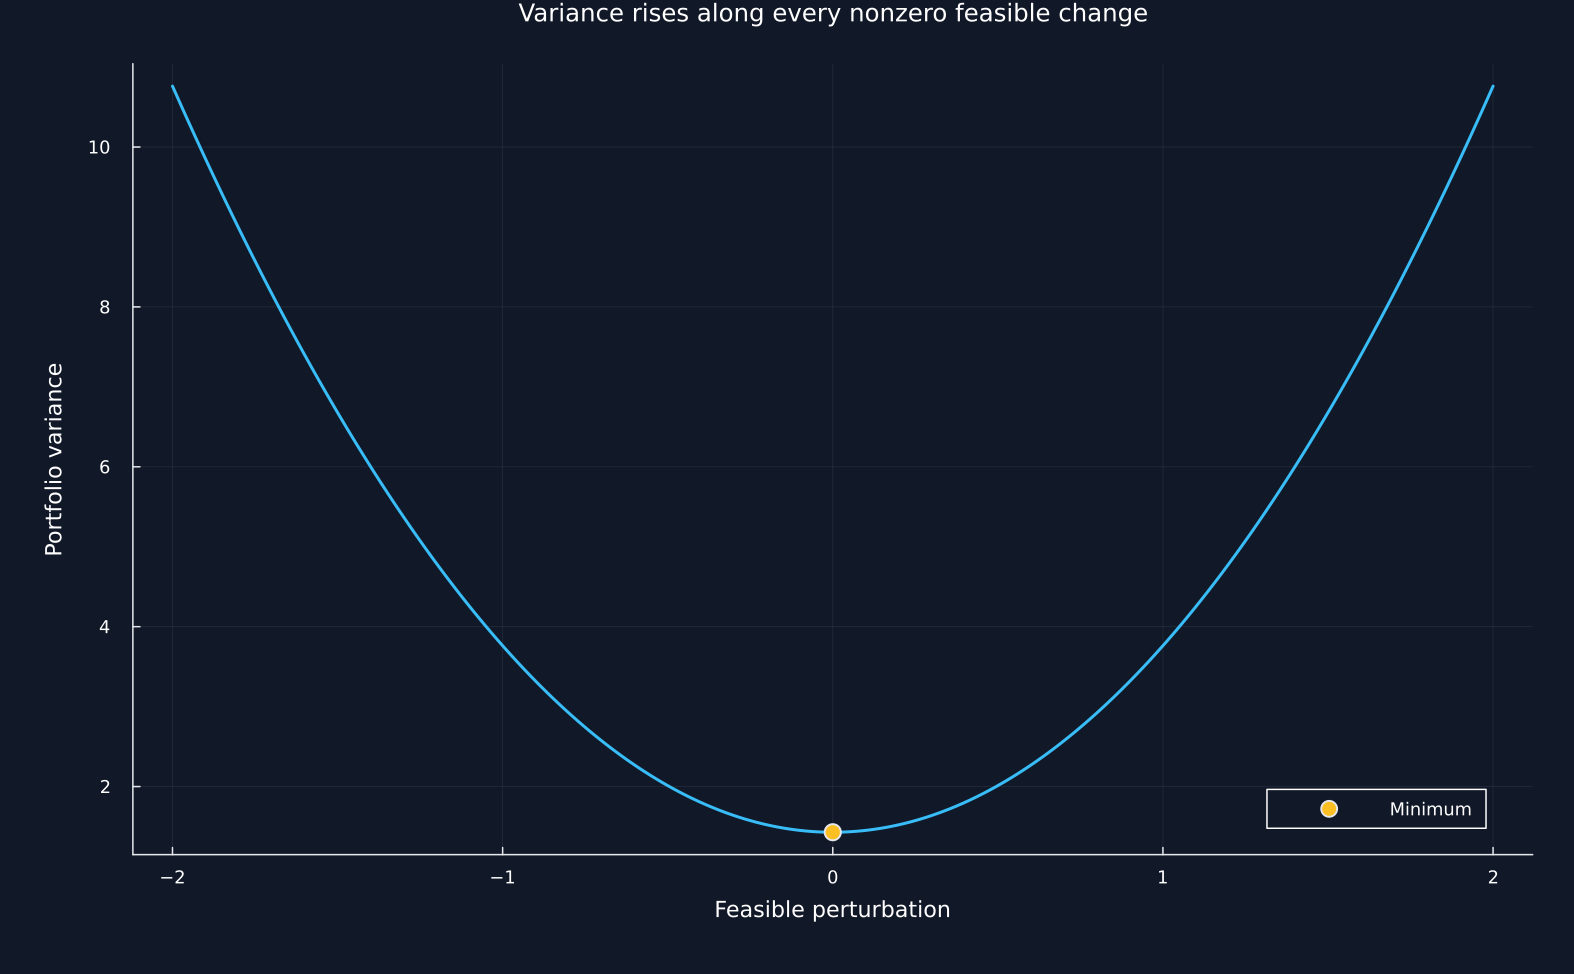

In [2]:
feasible_direction=svd(quick_exposures';full=true).V[:,end]
feasible_direction=feasible_direction/norm(feasible_direction)
perturbations=collect(range(-2.,2.;length=401))
feasible_weights=reduce(vcat,[permutedims(quick_weights+value*feasible_direction) for value in perturbations])
feasible_variances=[portfolio_variance(quick_covariance,vec(row)) for row in eachrow(feasible_weights)]
selected_indices=[1,101,201,301,401]
feasible_table=DataFrame("Perturbation"=>perturbations[selected_indices],"Portfolio variance"=>feasible_variances[selected_indices],"First exposure error"=>[abs((quick_exposures'*feasible_weights[index,:]-quick_targets)[1]) for index in selected_indices],"Second exposure error"=>[abs((quick_exposures'*feasible_weights[index,:]-quick_targets)[2]) for index in selected_indices])
table(feasible_table,"allocation_feasible_perturbations")
save_data(hcat(DataFrame("Perturbation"=>perturbations,"Portfolio variance"=>feasible_variances),DataFrame(feasible_weights,["Weight 1","Weight 2","Weight 3"])),paths,"allocation_feasible_variance")
figure=plot(perturbations,feasible_variances;color=palette.cyan,label="",xlabel="Feasible perturbation",ylabel="Portfolio variance",title="Variance rises along every nonzero feasible change",size=(1050,650))
scatter!(figure,[0.],[portfolio_variance(quick_covariance,quick_weights)];color=palette.amber,markersize=6,label="Minimum")
save_figure(figure,paths,"allocation_feasible_variance")


## Testing invariance under target rescaling

Scaling a target scales the weights, whereas scaling the whole covariance matrix leaves the weights unchanged:

$$
w^{\star}(V,B,ac)=a\,w^{\star}(V,B,c),
\qquad
w^{\star}(sV,B,c)=w^{\star}(V,B,c),
\quad s>0.
$$

Here, $a$ is any finite target scale, $s$ is a positive covariance-unit scale, and $w^{\star}(V,B,c)$ denotes the optimizer evaluated at covariance $V$, exposure matrix $B$, and target vector $c$.

Row,Second target,Asset 1 weight,Asset 2 weight,Asset 3 weight,Portfolio variance
,Float64,Float64,Float64,Float64,Float64
1,-1.5,0.428571,-1.07143,-0.428571,3.21429
2,-1.0,0.285714,-0.714286,-0.285714,1.42857
3,0.0,-0.0,-0.0,0.0,0.0
4,1.0,-0.285714,0.714286,0.285714,1.42857
5,1.5,-0.428571,1.07143,0.428571,3.21429


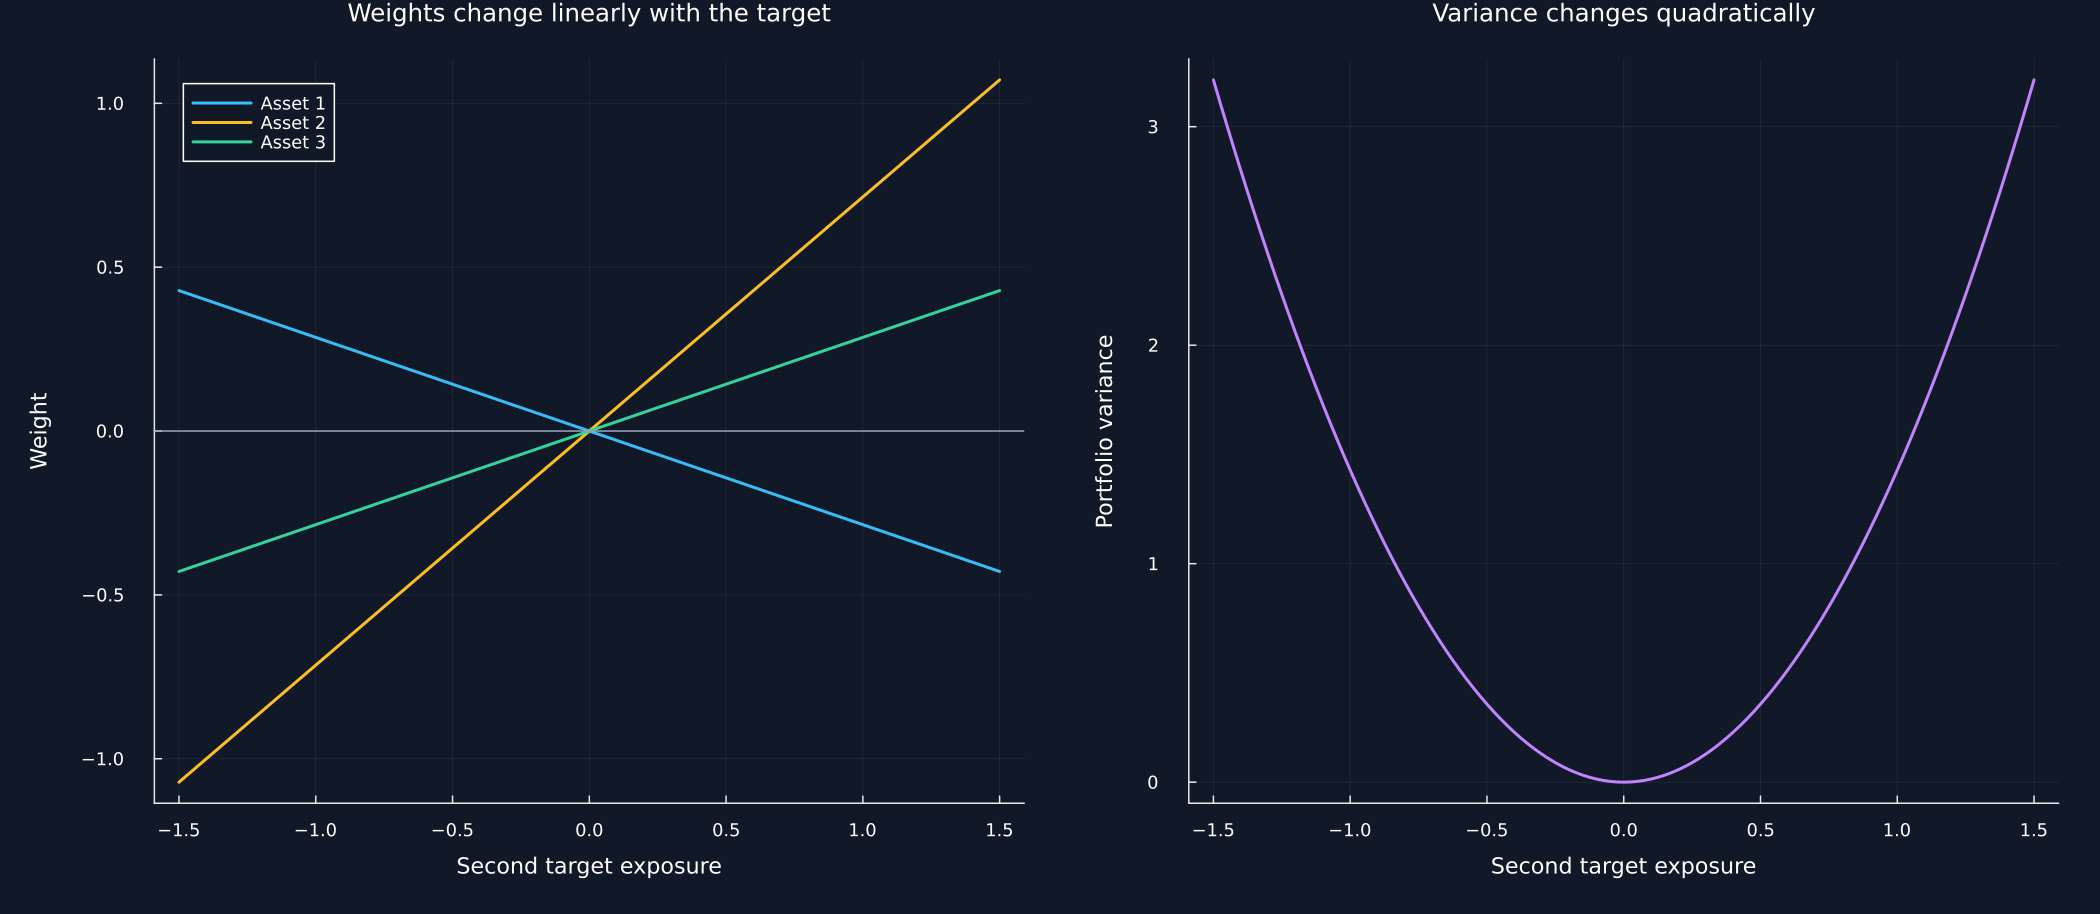

Row,Check,Scale,Largest weight difference,Passed
,String,Float64,Float64,String
1,Covariance unit change,1.0e-12,0.0,Yes
2,Covariance unit change,1.0,0.0,Yes
3,Covariance unit change,1.0e12,0.0,Yes
4,Target homogeneity,-3.0,0.0,Yes
5,Target homogeneity,0.25,0.0,Yes
6,Target homogeneity,4.0,0.0,Yes
7,Factor unit change,1.0,0.0,Yes
8,Asset and factor order,1.0,1.11022e-16,Yes


In [3]:
second_targets=collect(range(-1.5,1.5;length=121))
target_weights=reduce(vcat,[permutedims(minimum_variance_factor_weights(quick_covariance,quick_exposures,[0.,value])) for value in second_targets])
target_variances=[portfolio_variance(quick_covariance,vec(row)) for row in eachrow(target_weights)]
target_rows=[]
for value in [-1.5,-1.,0.,1.,1.5]
    weights=minimum_variance_factor_weights(quick_covariance,quick_exposures,[0.,value])
    push!(target_rows,(value,weights...,portfolio_variance(quick_covariance,weights)))
end
target_table=frame(["Second target","Asset 1 weight","Asset 2 weight","Asset 3 weight","Portfolio variance"],target_rows)
table(target_table,"allocation_target_sweep")
save_data(hcat(DataFrame("Second target"=>second_targets,"Portfolio variance"=>target_variances),DataFrame(target_weights,["Weight 1","Weight 2","Weight 3"])),paths,"allocation_target_paths")
left=plot(second_targets,target_weights;color=[palette.cyan palette.amber palette.green],label=["Asset 1" "Asset 2" "Asset 3"],xlabel="Second target exposure",ylabel="Weight",title="Weights change linearly with the target")
hline!(left,[0.];color=muted,label="",linewidth=1)
right=plot(second_targets,target_variances;color=violet,label="",xlabel="Second target exposure",ylabel="Portfolio variance",title="Variance changes quadratically")
save_figure(plot(left,right;layout=(1,2),size=(1400,610)),paths,"allocation_target_paths")
invariance_rows=[]
for scale in [1e-12,1.,1e12]
    observed=minimum_variance_factor_weights(scale*quick_covariance,quick_exposures,quick_targets)
    push!(invariance_rows,("Covariance unit change",scale,maximum(abs,observed-quick_weights),allclose(observed,quick_weights;rtol=1e-12,atol=1e-12)))
end
for scale in [-3.,.25,4.]
    observed=minimum_variance_factor_weights(quick_covariance,quick_exposures,scale*quick_targets)
    push!(invariance_rows,("Target homogeneity",scale,maximum(abs,observed-scale*quick_weights),allclose(observed,scale*quick_weights;rtol=1e-12,atol=1e-12)))
end
unit_scales=[1e6,1e-4]
unit_weights=minimum_variance_factor_weights(quick_covariance,quick_exposures.*unit_scales',quick_targets.*unit_scales)
push!(invariance_rows,("Factor unit change",1.,maximum(abs,unit_weights-quick_weights),allclose(unit_weights,quick_weights;rtol=1e-12,atol=1e-12)))
asset_order=[3,1,2]
factor_order=[2,1]
permuted=minimum_variance_factor_weights(quick_covariance[asset_order,asset_order],quick_exposures[asset_order,factor_order],quick_targets[factor_order])
restored=similar(permuted)
restored[asset_order]=permuted
push!(invariance_rows,("Asset and factor order",1.,maximum(abs,restored-quick_weights),allclose(restored,quick_weights;rtol=1e-12,atol=1e-12)))
invariance_table=frame(["Check","Scale","Largest weight difference","Passed"],invariance_rows)
table(invariance_table,"allocation_invariance_checks")


## Square Exposure Systems

When the number of independent factor constraints equals the number of assets, the constraints determine the weights directly:

$$
K=N,
\qquad
w^{\star}=B^{-\mathsf T}c.
$$

Here, $K$ is the number of factor columns, $N$ is the number of assets, $B^{-\mathsf T}$ is the inverse transpose of the square exposure matrix, and $c$ is the target vector; covariance information no longer changes the solution because no free portfolio direction remains.

In [4]:
square_exposures=[1. .4;-.2 1.]
square_targets=[0.,1.]
square_covariances=[[1. .2;.2 2.],[8. -1.;-1. .5]]
direct_square=square_exposures'\square_targets
square_rows=[]
for (index,covariance) in enumerate(square_covariances)
    weights=minimum_variance_factor_weights(covariance,square_exposures,square_targets)
    push!(square_rows,(index,weights...,maximum(abs,weights-direct_square),portfolio_variance(covariance,weights)))
end
square_table=frame(["Covariance case","Asset 1 weight","Asset 2 weight","Largest difference from direct constraints","Portfolio variance"],square_rows)
table(square_table,"allocation_square_system")


Row,Covariance case,Asset 1 weight,Asset 2 weight,Largest difference from direct constraints,Portfolio variance
,Int64,Float64,Float64,Float64,Float64
1,1,0.185185,0.925926,0.0,1.81756
2,2,0.185185,0.925926,0.0,0.360082


## Public Industry Covariance Example

The public return history supplies an observed covariance estimate and the resulting portfolio variance:

$$
\widehat V=252\frac{1}{T-1}\sum_{t=1}^{T}(r_t-\bar r)(r_t-\bar r)^{\mathsf T},
\qquad
\widehat\sigma_p^2=w^{\mathsf T}\widehat Vw.
$$

Here, $T$ is the number of complete daily observations, $r_t$ is the vector of industry returns on date $t$, $\bar r$ is their sample mean, $\widehat V$ is the annualized sample covariance matrix, $w$ is a portfolio weight vector, and $\widehat\sigma_p^2$ is its estimated annual variance.

Row,Field,Value
,String,Any
1,Archive,49 Industry Portfolios daily archive
2,Provider,Kenneth R. French Data Library
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Complete dates,1760
7,Industry portfolios,12


Row,Industry,Budget-only weight,Three-constraint weight,Supplied exposure one,Supplied exposure two
,String,Float64,Float64,Float64,Float64
1,Agric,0.00168582,-0.0423465,-1.0,1.0
2,Food,0.568855,0.422701,-0.818182,0.959493
3,Soda,0.149008,0.0774131,-0.636364,0.841254
4,Beer,-0.13242,-0.104523,-0.454545,0.654861
5,Smoke,0.0799081,0.0939617,-0.272727,0.415415
6,Toys,-0.018136,-0.0437411,-0.0909091,0.142315
7,Fun,0.0912849,0.0730963,0.0909091,-0.142315
8,Books,0.0755272,0.0833424,0.272727,-0.415415
9,Hshld,0.192724,0.295234,0.454545,-0.654861


Row,Constraint,Target,Achieved exposure,Absolute difference
,String,Float64,Float64,Float64
1,Budget,1.0,1.0,4.44089e-16
2,Supplied exposure one,0.0,4.16334e-16,4.16334e-16
3,Supplied exposure two,0.0,-2.498e-16,2.498e-16


Row,Portfolio,Annual variance,Annual volatility,Gross exposure,Largest absolute weight
,String,Float64,Float64,Float64,Float64
1,Budget only,0.0242177,0.155621,1.45769,0.568855
2,Three supplied targets,0.0249739,0.158031,1.5196,0.422701


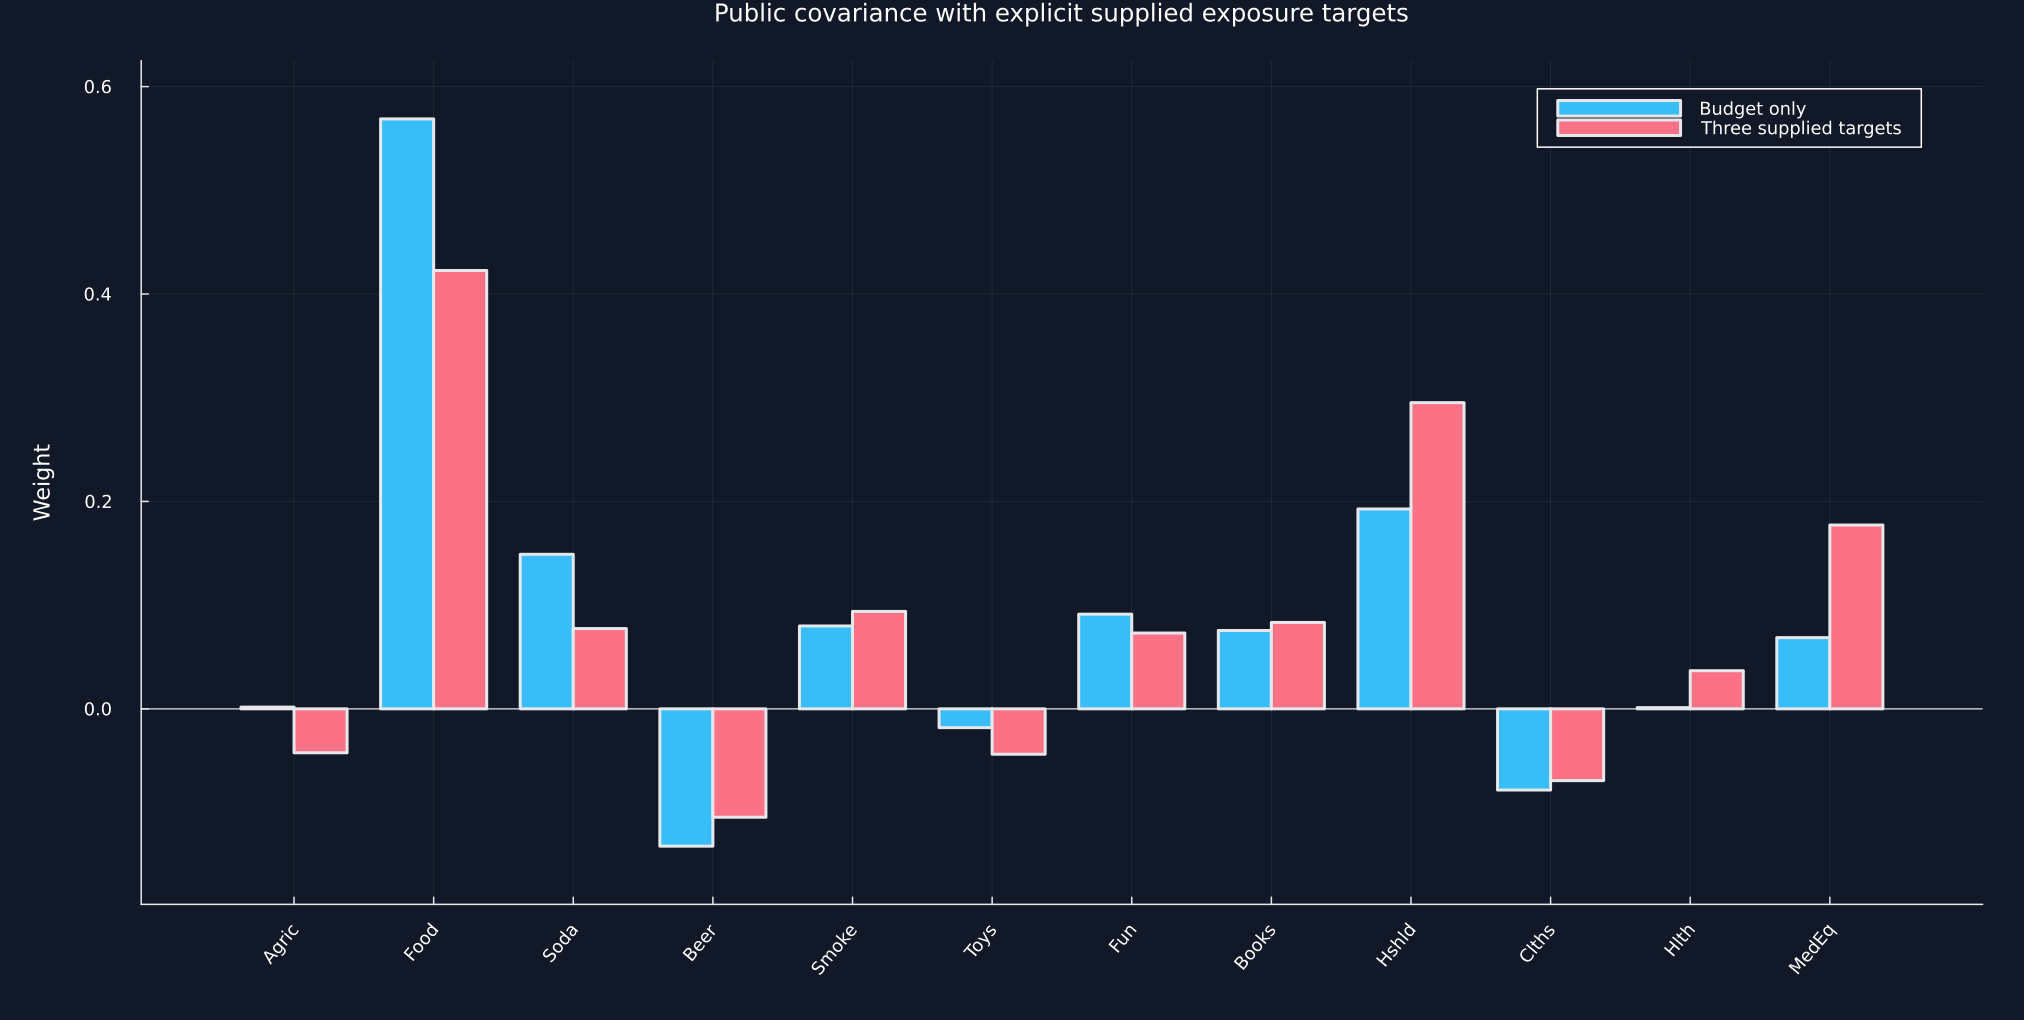

Row,Supplied exposure-one target,Annual variance,Annual volatility,Gross exposure
,Float64,Float64,Float64,Float64
1,-0.6,0.0866744,0.294405,6.76493
2,-0.3,0.0389662,0.197399,3.75437
3,0.0,0.0249739,0.158031,1.5196
4,0.3,0.0446973,0.211417,2.84345
5,0.6,0.0981365,0.313268,5.5975


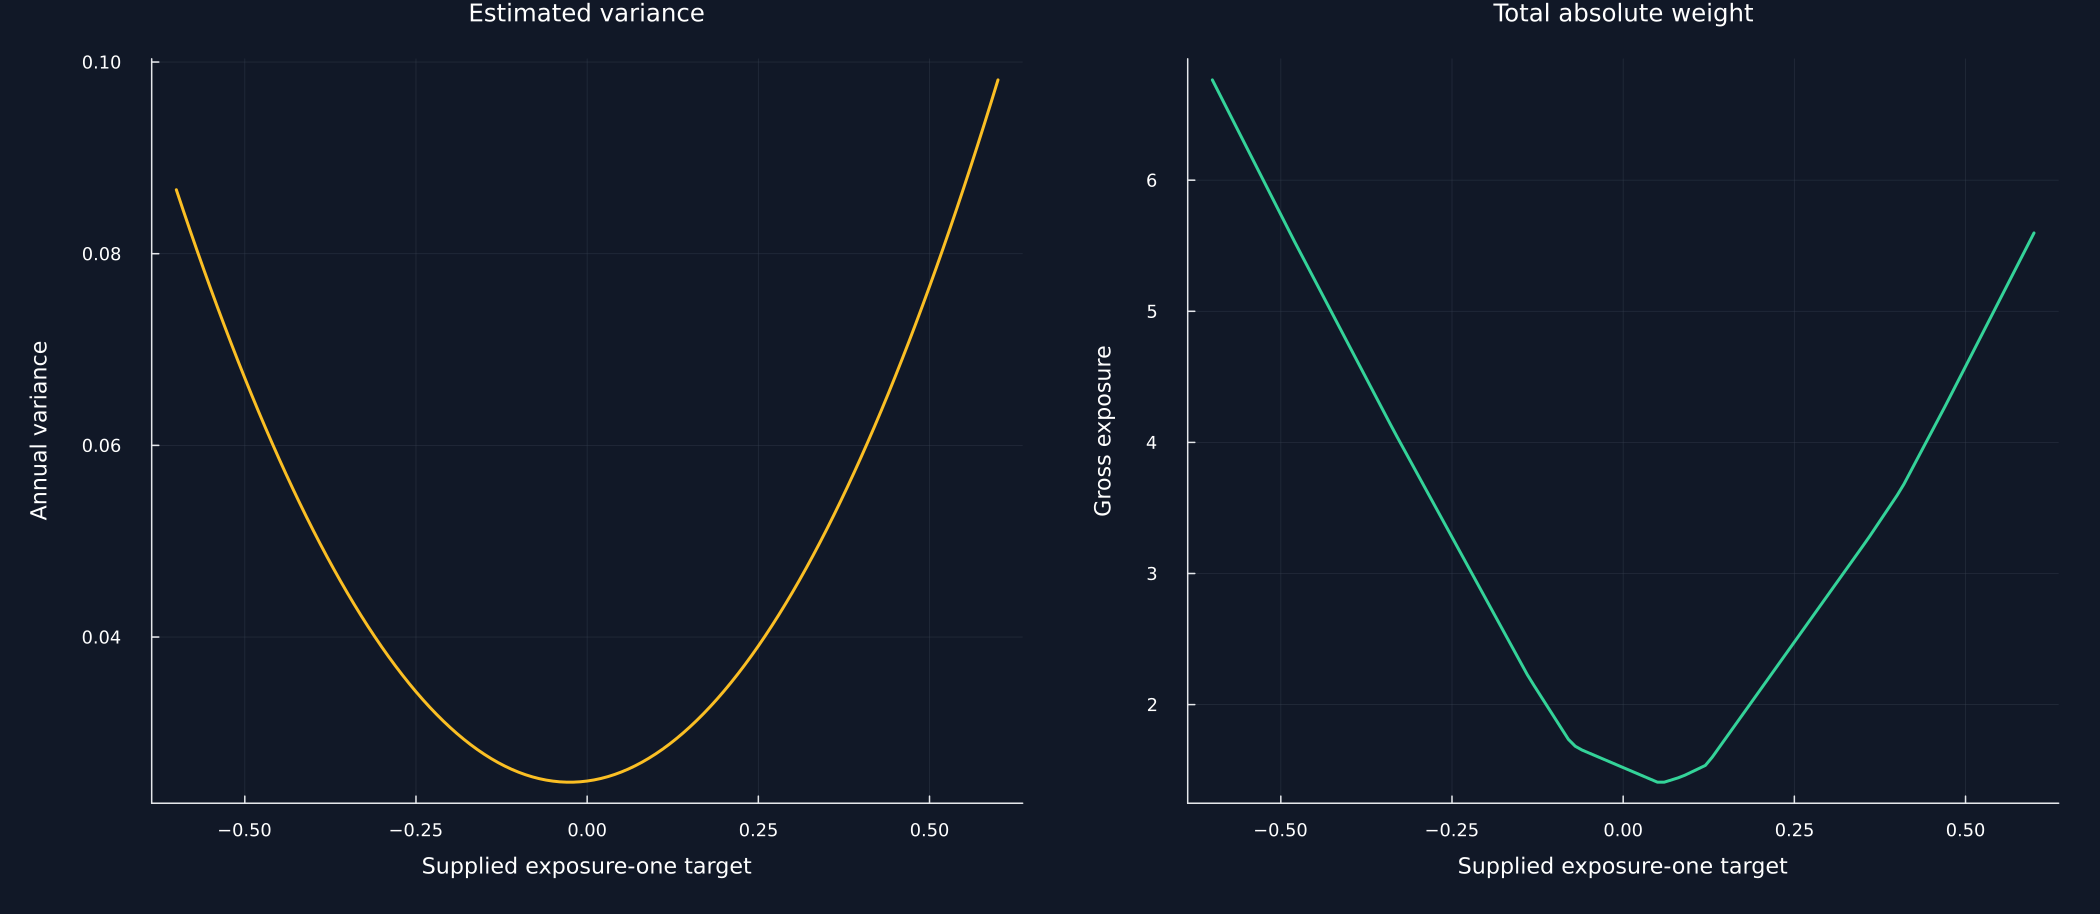

In [5]:
public_dates,industry_labels,industry_returns=search_returns()
public_assets=industry_labels[1:12]
public_sample=industry_returns[:,1:12]
public_covariance=cov(public_sample)*252
asset_count=length(public_assets)
supplied_first=collect(range(-1.,1.;length=asset_count))
supplied_second=cos.(range(0.,pi;length=asset_count))
supplied_first.-=mean(supplied_first)
supplied_second.-=mean(supplied_second)
public_exposures=hcat(ones(asset_count),supplied_first,supplied_second)
public_targets=[1.,0.,0.]
public_weights=minimum_variance_factor_weights(public_covariance,public_exposures,public_targets)
budget_only_weights=minimum_variance_factor_weights(public_covariance,ones(asset_count,1),[1.])
public_achieved=public_exposures'*public_weights
data_provenance=frame(["Field","Value"],[("Archive","49 Industry Portfolios daily archive"),("Provider","Kenneth R. French Data Library"),("Return type","Daily value-weighted return"),("Analysis start",string(first(public_dates))),("Analysis end",string(last(public_dates))),("Complete dates",length(public_dates)),("Industry portfolios",asset_count)])
table(data_provenance,"allocation_data_provenance")
public_weight_table=DataFrame("Industry"=>public_assets,"Budget-only weight"=>budget_only_weights,"Three-constraint weight"=>public_weights,"Supplied exposure one"=>supplied_first,"Supplied exposure two"=>supplied_second)
table(public_weight_table,"allocation_public_weights")
public_exposure_table=DataFrame("Constraint"=>["Budget","Supplied exposure one","Supplied exposure two"],"Target"=>public_targets,"Achieved exposure"=>public_achieved,"Absolute difference"=>abs.(public_achieved-public_targets))
table(public_exposure_table,"allocation_public_exposures")
public_summary=frame(["Portfolio","Annual variance","Annual volatility","Gross exposure","Largest absolute weight"],[(name,portfolio_variance(public_covariance,weights),sqrt(portfolio_variance(public_covariance,weights)),sum(abs,weights),maximum(abs,weights)) for (name,weights) in [("Budget only",budget_only_weights),("Three supplied targets",public_weights)]])
table(public_summary,"allocation_public_summary")
save_data(hcat(DataFrame("Date"=>public_dates),DataFrame(public_sample,public_assets)),paths,"allocation_public_returns")
save_data(DataFrame(public_covariance,public_assets),paths,"allocation_public_covariance")
figure=paired_weights(public_assets,budget_only_weights,public_weights;first_label="Budget only",second_label="Three supplied targets",title="Public covariance with explicit supplied exposure targets",size=(1350,680))
save_figure(figure,paths,"allocation_public_weights")
public_target_values=collect(range(-.6,.6;length=121))
public_target_weights=reduce(vcat,[permutedims(minimum_variance_factor_weights(public_covariance,public_exposures,[1.,value,0.])) for value in public_target_values])
public_target_variances=[portfolio_variance(public_covariance,vec(row)) for row in eachrow(public_target_weights)]
public_target_rows=[]
for value in [-.6,-.3,0.,.3,.6]
    weights=minimum_variance_factor_weights(public_covariance,public_exposures,[1.,value,0.])
    push!(public_target_rows,(value,portfolio_variance(public_covariance,weights),sqrt(portfolio_variance(public_covariance,weights)),sum(abs,weights)))
end
public_target_table=frame(["Supplied exposure-one target","Annual variance","Annual volatility","Gross exposure"],public_target_rows)
table(public_target_table,"allocation_public_target_sweep")
public_gross=vec(sum(abs.(public_target_weights);dims=2))
save_data(hcat(DataFrame("Target"=>public_target_values,"Variance"=>public_target_variances,"Gross exposure"=>public_gross),DataFrame(public_target_weights,public_assets)),paths,"allocation_public_target_variance")
left=plot(public_target_values,public_target_variances;color=palette.amber,label="",xlabel="Supplied exposure-one target",ylabel="Annual variance",title="Estimated variance")
right=plot(public_target_values,public_gross;color=palette.green,label="",xlabel="Supplied exposure-one target",ylabel="Gross exposure",title="Total absolute weight")
save_figure(plot(left,right;layout=(1,2),size=(1400,610)),paths,"allocation_public_target_variance")


## Checking the portfolio solution near numerical boundaries

A computed allocation is accepted only when every scaled exposure residual is small relative to its target:

$$
\left|\widetilde B^{\mathsf T}w-\widetilde c\right|_j
\leq
\begin{cases}
10^{-10}|\widetilde c_j|,&\widetilde c_j\ne0,\\
10^{-12},&\widetilde c_j=0.
\end{cases}
$$

Here, $\widetilde B$ and $\widetilde c$ are the exposure matrix and target vector after positive column scaling, $j$ labels a constraint, and the two tolerances protect nonzero and zero targets without changing their units.

Row,Column separation,Exposure condition number,Gross exposure,Largest exposure residual,Accepted
,Float64,Float64,Float64,Float64,String
1,1.0,3.40301,2.11427,4.44089e-16,Yes
2,0.01,327.543,2.11427,2.13371e-16,Yes
3,0.0001,32773.5,2.11427,4.44089e-16,Yes
4,1.0e-6,3.27737e6,2.11427,1.11022e-16,Yes
5,1.0e-8,3.27737e8,NaN,NaN,No
6,1.0e-10,3.27737e10,NaN,NaN,No
7,1.0e-12,3.277e12,NaN,NaN,No


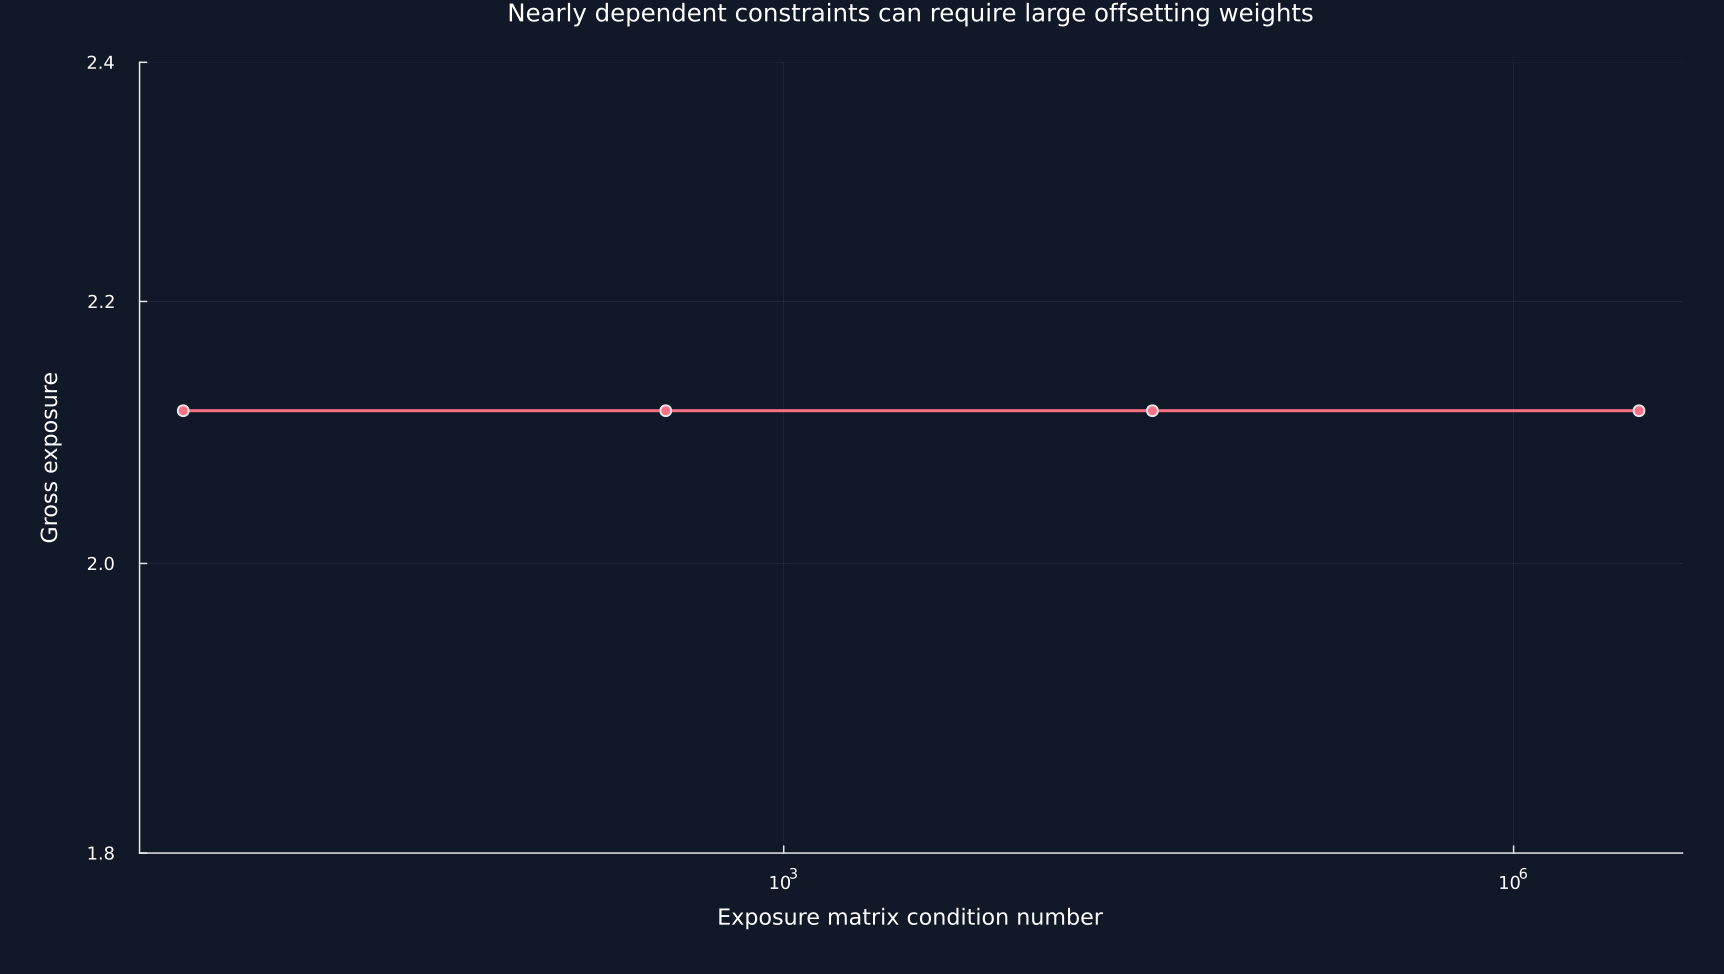

Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Nonsymmetric covariance,ArgumentError,ArgumentError,Yes
2,Singular covariance,ArgumentError,ArgumentError,Yes
3,Redundant exposure columns,ArgumentError,ArgumentError,Yes
4,Wrong target length,ArgumentError,ArgumentError,Yes
5,Nonfinite target,ArgumentError,ArgumentError,Yes
6,Complex exposure,ArgumentError,ArgumentError,Yes


Row,Public group,Count,Notebook coverage
,String,Int64,String
1,Minimum-variance allocation function,1,"Formula, first-order conditions, perturbations, targets, units, public covariance, and boundaries"
2,Released optimizer checks,33,Numerical identities and representative boundary families


Row,Question,Answer
,String,String
1,What determines the solution?,"Covariance, supplied exposure matrix, and target vector"
2,What must hold?,Positive-definite covariance and independent exposure columns
3,What does public return history provide?,An observed covariance estimate
4,What does the calculation not establish?,Whether the supplied exposures are causally correct


In [6]:
include(joinpath("..","support","BookConditionDiagnostics.jl"))
condition_rows=[]
condition_levels=[1.,1e-2,1e-4,1e-6,1e-8,1e-10,1e-12]
condition_covariance=Matrix(Diagonal([1.,1.3,1.8,2.4]))
base_one=[1.,-1.,.5,-.5]
base_two=[.5,.2,-.8,.1]
for separation in condition_levels
    exposures=hcat(ones(4),base_one,base_one+separation*base_two)
    try
        weights=minimum_variance_factor_weights(condition_covariance,exposures,[1.,0.,separation])
        residual=maximum(abs,exposures'*weights-[1.,0.,separation])
        push!(condition_rows,(separation,BookConditionDiagnostics.exposure_condition(exposures),sum(abs,weights),residual,true))
    catch error
        error isa ArgumentError || rethrow()
        push!(condition_rows,(separation,BookConditionDiagnostics.exposure_condition(exposures),NaN,NaN,false))
    end
end
condition_table=frame(["Column separation","Exposure condition number","Gross exposure","Largest exposure residual","Accepted"],condition_rows)
table(condition_table,"allocation_condition_sensitivity")
accepted_condition=condition_table[condition_table.Accepted,:]
figure=plot(accepted_condition[:,2],accepted_condition[:,3];marker=:circle,color=palette.rose,label="",xscale=:log10,yscale=:log10,xlabel="Exposure matrix condition number",ylabel="Gross exposure",title="Nearly dependent constraints can require large offsetting weights",size=(1150,650))
plot!(figure;ylims=(1.8,2.4),yticks=([1.8,2.,2.2,2.4],["1.8","2.0","2.2","2.4"]))
save_figure(figure,paths,"allocation_condition_sensitivity")
input_checks=frame(["Check","Expected result","Observed result","Passed"],[contract_result("Nonsymmetric covariance",()->minimum_variance_factor_weights([1. .4;.1 1.],Matrix{Float64}(I,2,2),[1.,0.])),contract_result("Singular covariance",()->minimum_variance_factor_weights([1. 1.;1. 1.],Matrix{Float64}(I,2,2),[1.,0.])),contract_result("Redundant exposure columns",()->minimum_variance_factor_weights(Matrix{Float64}(I,3,3),[1. 1.;0. 0.;1. 1.],[0.,1.])),contract_result("Wrong target length",()->minimum_variance_factor_weights(Matrix{Float64}(I,2,2),Matrix{Float64}(I,2,2),[1.])),contract_result("Nonfinite target",()->minimum_variance_factor_weights(Matrix{Float64}(I,2,2),Matrix{Float64}(I,2,2),[1.,NaN])),contract_result("Complex exposure",()->minimum_variance_factor_weights(Matrix{Float64}(I,2,2),[1+im 0.;0. 1.],[1.,0.]))])
table(input_checks,"allocation_input_checks")
public_surface = frame(["Public group","Count","Notebook coverage"],[["Minimum-variance allocation function",1,"Formula, first-order conditions, perturbations, targets, units, public covariance, and boundaries"],["Released optimizer checks",33,"Numerical identities and representative boundary families"]])
table(public_surface,"allocation_public_surface")
section_summary = frame(["Question","Answer"],[["What determines the solution?","Covariance, supplied exposure matrix, and target vector"],["What must hold?","Positive-definite covariance and independent exposure columns"],["What does public return history provide?","An observed covariance estimate"],["What does the calculation not establish?","Whether the supplied exposures are causally correct"]])
table(section_summary,"allocation_section_summary")


## Tests

In [7]:
@assert allclose(quick_weights,[-2/7,5/7,2/7];rtol=1e-7,atol=2e-15)
@assert allclose(quick_achieved,quick_targets;rtol=1e-7,atol=2e-15)
@assert allclose(quick_weights,oracle_weights;rtol=1e-7,atol=2e-15)
@assert maximum(abs,quick_stationarity)<2e-15
@assert argmin(feasible_variances)==201
@assert all(invariance_table.Passed)
@assert allclose(public_achieved,public_targets;rtol=1e-7,atol=2e-12)
@assert all(input_checks.Passed)
@assert sum(public_surface.Count)==34
@assert all(name->isfile(joinpath(paths.figures,name*".pdf")),["allocation_feasible_variance","allocation_target_paths","allocation_public_weights","allocation_public_target_variance","allocation_condition_sensitivity"])
@assert all(name->isfile(joinpath(paths.tables,name*".tex")),["allocation_quickstart_weights","allocation_kkt_checks","allocation_feasible_perturbations","allocation_target_sweep","allocation_invariance_checks","allocation_square_system","allocation_data_provenance","allocation_public_weights","allocation_public_exposures","allocation_public_summary","allocation_public_target_sweep","allocation_condition_sensitivity","allocation_input_checks","allocation_public_surface","allocation_section_summary"])
